In [1]:
import wandb
import json
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rc
rc('text', usetex=True)
import matplotlib.pylab as pylab
params = {'legend.fontsize': '11',
          'figure.figsize': (12,5),
          'axes.labelsize': 16,
          'axes.titlesize': 16,
          'xtick.labelsize': 13,
          'ytick.labelsize': 13}
pylab.rcParams.update(params)
import numpy as np
from scipy.stats import gaussian_kde

/var/folders/tw/q955b5d55gn3m9tkc27d9b440000gq/T/ipykernel_34613/107340925.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = matplotlib.cm.get_cmap('Blues')
/var/folders/tw/q955b5d55gn3m9tkc27d9b440000gq/T/ipykernel_34613/107340925.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap1 = matplotlib.cm.get_cmap('BuPu')


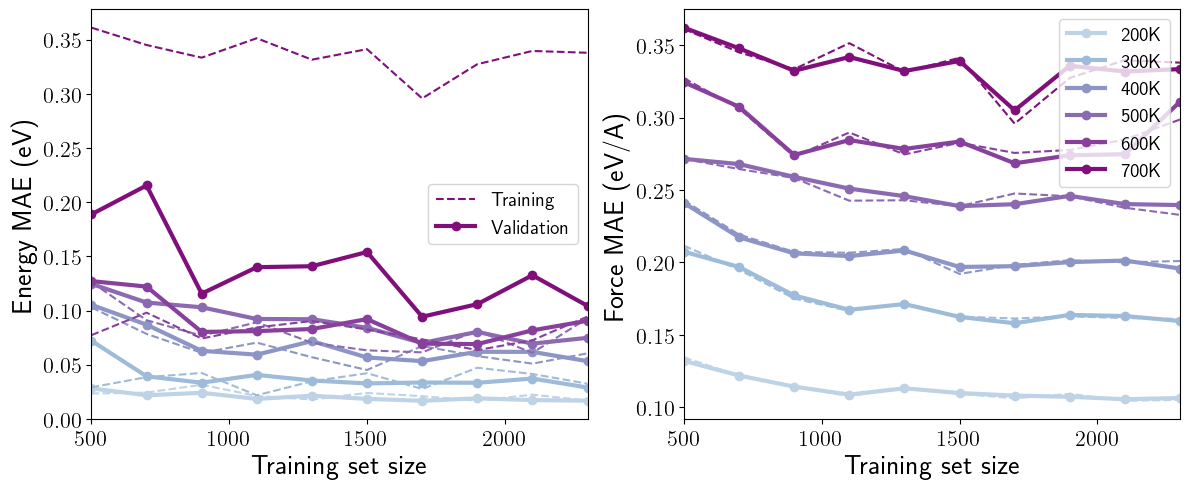

In [3]:
api = wandb.Api()
cmap2 = matplotlib.cm.get_cmap('Blues')
cmap1 = matplotlib.cm.get_cmap('BuPu')

line_width=3

more_force = False

for temp in [200,300,400,500,600,700]:
    if more_force:
        if temp != 300:
            run_name = "ai_at_mmfi/llzo_"+str(temp)+"k_md"
        else:
            run_name = "ai_at_mmfi/LLZO_"+str(temp)+"K_MD"
    else:
        run_name = "ai_at_mmfi/llzo_"+str(temp)+"k_md_equal_w"
    runs = api.runs(run_name)

    n_train, train_E, train_F, validation_E, validation_F = [], [], [], [], []
    n_train_sorted, train_E_sorted, train_F_sorted, validation_E_sorted, validation_F_sorted = [], [], [], [], []

    for run in runs: 
        # .summary contains the output keys/values for metrics like accuracy.
        #  We call ._json_dict to omit large files 
        try:
            rs=run.summary._json_dict
            _l=[json.loads(run.json_config)["dataset"]["value"]["split"]["n_train"],rs['Training E'], rs['Training F'], rs['Validation E'], rs['Validation F']]
            _n_train = json.loads(run.json_config)["dataset"]["value"]["split"]["n_train"]
            n_train.append(_n_train)
            train_E.append(rs['Training E'])
            train_F.append(rs['Training F'])
            validation_E.append(rs['Validation E'])
            validation_F.append(rs['Validation F'])
        except:
            pass

    n_train_sorted = list(sorted(n_train))
    for item in n_train_sorted:
        for i, j in enumerate(n_train):
            if j == item:
                train_E_sorted.append(train_E[i])
                train_F_sorted.append(train_F[i])
                validation_E_sorted.append(validation_E[i])
                validation_F_sorted.append(validation_F[i])
    
    plt.subplot(1,2,1)
    
    if temp!=700:
        plt.plot(n_train_sorted,train_E_sorted,'--',color=cmap1(temp/800))
        plt.plot(n_train_sorted,validation_E_sorted,'o-',lw=line_width,color=cmap1(temp/800))

    if temp==700:
        plt.plot(n_train_sorted,train_F_sorted,'--',color=cmap1(temp/800),label='Training')
        plt.plot(n_train_sorted,validation_E_sorted,'o-',lw=line_width,color=cmap1(temp/800),label='Validation')
    
        plt.xlabel('Training set size')
        plt.ylabel('Energy MAE (eV)')
        #plt.yscale('log')
        plt.legend()
        
        #plt.plot(n_train_sorted,[33.629 for _ in n_train_sorted],'r-')
    
    plt.xlim([500,2300])
    if more_force:
        plt.ylim([0.045,0.22])
    plt.subplot(1,2,2)
    plt.plot(n_train_sorted,train_F_sorted,'--',color=cmap1(temp/800))
    plt.plot(n_train_sorted,validation_F_sorted,'o-',lw=line_width,color=cmap1(temp/800),label=str(temp)+'K')
    
    if temp==700:
        plt.xlabel('Training set size')
        plt.ylabel('Force MAE (eV/A)')
        #plt.yscale('log')
        plt.legend()
        #plt.plot(n_train_sorted,[11.622 for _ in n_train_sorted],'r-')
        
    plt.xlim([500,2300])
    if more_force:
        plt.ylim([0.045,0.22])

plt.tight_layout()

if more_force:
    plt.savefig('tr_curves_individual_temp_more_force.pdf')
else:
    plt.savefig('tr_curves_individual_temp_equal_weight.pdf')


/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_63119/321504859.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = matplotlib.cm.get_cmap('Blues')
/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_63119/321504859.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap1 = matplotlib.cm.get_cmap('BuPu')


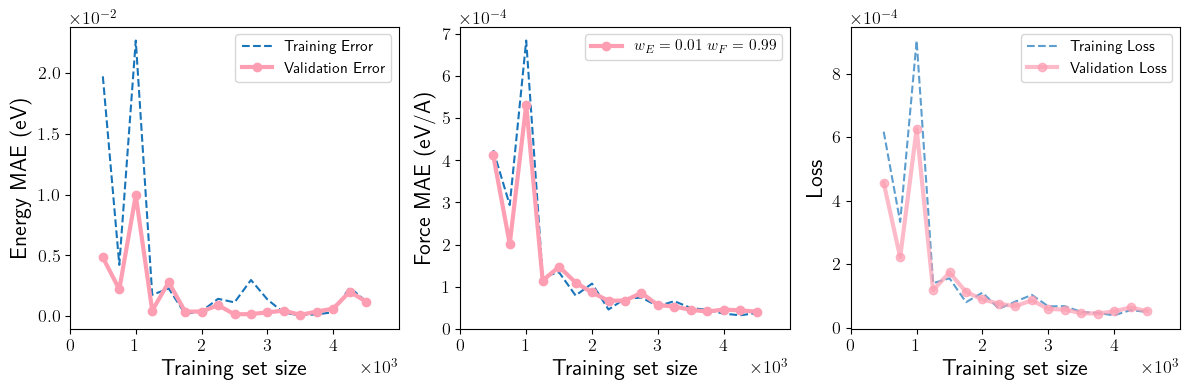

In [23]:
import wandb
api = wandb.Api()
cmap2 = matplotlib.cm.get_cmap('Blues')
cmap1 = matplotlib.cm.get_cmap('BuPu')
line_width=3
#run_names = ['llzo_all_temp_md','llzo_all_temp_md_equal_w']
#run_names = ['llzo_12_44_opt_equal_w']
#run_names = ['llzo_12_44_opt_high_w_e']
#run_names = ['llzo_12_44_opt_complex_nn']
run_names = ['llzo_opt_data_redo']
run_names = ['ai_at_mmfi/'+i for i in run_names]

for idx, run_name in enumerate(run_names):
    runs = api.runs(run_name)

    n_train, train_E, train_F, validation_E, validation_F, training_loss, validation_loss = [], [], [], [], [], [], []
    n_train_sorted, train_E_sorted, train_F_sorted, validation_E_sorted, validation_F_sorted, training_loss_sorted, validation_loss_sorted = [], [], [], [], [], [], []
    for run in runs: 
        # .summary contains the output keys/values for metrics like accuracy.
        #  We call ._json_dict to omit large files 
        try:
            rs=run.summary._json_dict
            #print(idx,run,rs)
            _l=[json.loads(run.json_config)["dataset"]["value"]["split"]["n_train"],rs['Training E'], rs['Training F'], rs['Validation E'], rs['Validation F']]
            _n_train = json.loads(run.json_config)["dataset"]["value"]["split"]["n_train"]
            n_train.append(_n_train)
            train_E.append(rs['Training E'])
            train_F.append(rs['Training F'])
            validation_E.append(rs['Validation E'])
            validation_F.append(rs['Validation F'])
            training_loss.append(rs['Training loss'])
            validation_loss.append(rs['Validation loss'])
        except:
            pass

    n_train_sorted = list(sorted(n_train))
    for item in n_train_sorted:
        for i, j in enumerate(n_train):
            if j == item:
                train_E_sorted.append(train_E[i])
                train_F_sorted.append(train_F[i])
                validation_E_sorted.append(validation_E[i])
                validation_F_sorted.append(validation_F[i])
                training_loss_sorted.append(training_loss[i])
                validation_loss_sorted.append(validation_loss[i])
                
    if idx==0:
        clr='#CB0000'
    elif idx==1:
        clr='#4d85bd'

    tr_clr='#1975BA'
    valid_clr='#FD9EB2'
    
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    if idx==0:
        plt.plot(n_train_sorted,train_E_sorted,'--',c=tr_clr,label='Training Error')
        plt.plot(n_train_sorted,validation_E_sorted,'o-',lw=line_width,c=valid_clr,label='Validation Error')
    #else:
    #    plt.plot(n_train_sorted,train_E_sorted,'--',c=clr)
    #    plt.plot(n_train_sorted,validation_E_sorted,'o-',lw=line_width,c=clr)
    plt.xlabel('Training set size')
    plt.ylabel('Energy MAE (eV)')
    plt.ticklabel_format(style='sci',scilimits=(0,0))
    plt.xticks([0,1000,2000,3000,4000])
    plt.xlim([0,5000])
    #plt.ylim([0.015,0.07])
    
    plt.legend()
    
    plt.subplot(1,3,2)
    #if idx==1:
    #    lb="$w_{E}=0.5$"+' '+"$w_{F}=0.5$"
    if idx==0:
        lb="$w_{E}=0.01$"+' '+"$w_{F}=0.99$"
    plt.plot(n_train_sorted,train_F_sorted,'--',c=tr_clr)
    plt.plot(n_train_sorted,validation_F_sorted,'o-',lw=line_width,c=valid_clr,label=lb)
    plt.xlabel('Training set size')
    plt.ylabel('Force MAE (eV/A)')
    plt.ticklabel_format(style='sci',scilimits=(0,0))
    plt.xticks([0,1000,2000,3000,4000])
    plt.xlim([0,5000])
    plt.legend()

    plt.subplot(1,3,3)
    if idx==0:
        plt.plot(n_train_sorted,training_loss_sorted,'--',c=tr_clr,label='Training Loss',alpha=0.7)
        plt.plot(n_train_sorted,validation_loss_sorted,'o-',lw=line_width,c=valid_clr,label='Validation Loss',alpha=0.7)
    #else:
    #    plt.plot(n_train_sorted,train_E_sorted,'--',c=clr)
    #    plt.plot(n_train_sorted,validation_E_sorted,'o-',lw=line_width,c=clr)
    plt.xlabel('Training set size')
    plt.ylabel('Loss')
    plt.ticklabel_format(style='sci',scilimits=(0,0))
    plt.xticks([0,1000,2000,3000,4000])
    plt.xlim([0,5000])
    #plt.ylim([0.00075,0.00185])
    plt.legend()
    
plt.tight_layout()
plt.savefig('llzo_12_44_opt_learning_curves_deeper_nn_inv_equvariant_redo.pdf')

/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_23536/3875230637.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = matplotlib.cm.get_cmap('Blues')
/var/folders/q5/dn8rdk613pj4bx_9jv6fyz1h0000gp/T/ipykernel_23536/3875230637.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap1 = matplotlib.cm.get_cmap('BuPu')


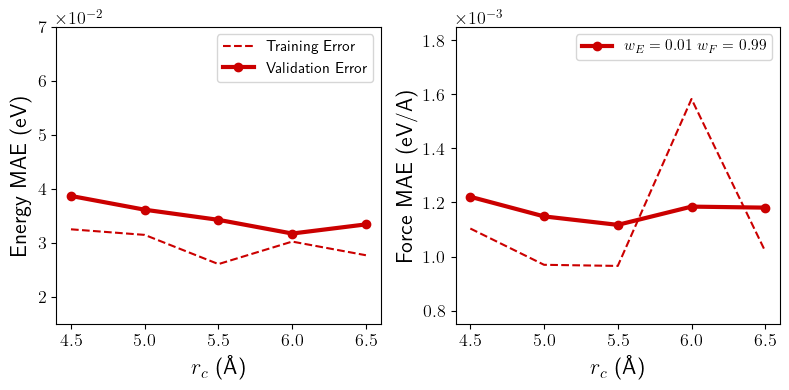

In [29]:
#Energy and forces MAE for using different cutoff radius, using 4000 test data, 4000 epochs for training
api = wandb.Api()
cmap2 = matplotlib.cm.get_cmap('Blues')
cmap1 = matplotlib.cm.get_cmap('BuPu')
line_width=3
#run_names = ['llzo_all_temp_md','llzo_all_temp_md_equal_w']
run_names = ['llzo_12_44_opt_rc_scan']
run_names = ['ai_at_mmfi/'+i for i in run_names]

for idx, run_name in enumerate(run_names):
    runs = api.runs(run_name)

    r_c, train_E, train_F, validation_E, validation_F = [], [], [], [], []
    r_c_sorted, train_E_sorted, train_F_sorted, validation_E_sorted, validation_F_sorted= [], [], [], [], []
    for run in runs: 
        # .summary contains the output keys/values for metrics like accuracy.
        #  We call ._json_dict to omit large files 
        try:
            rs=run.summary._json_dict
            #print(idx,run,rs)
            #_l=[json.loads(run.json_config)["dataset"]["value"]["split"]["n_train"],rs['Training E'], rs['Training F'], rs['Validation E'], rs['Validation F']]
            #print(json.loads(run.json_config)["dataset"]["value"]["split"]['r_cut'])
            train_E.append(rs['Training E'])
            train_F.append(rs['Training F'])
            validation_E.append(rs['Validation E'])
            validation_F.append(rs['Validation F'])
            r_c.append(float(json.loads(run.json_config)["dataset"]["value"]["split"]['r_cut']))
        except:
            pass

        #print(train_E)
        
    r_c_sorted = list(sorted(r_c))
    for item in r_c_sorted:
        for i, j in enumerate(r_c):
            if j == item:
                train_E_sorted.append(train_E[i])
                train_F_sorted.append(train_F[i])
                validation_E_sorted.append(validation_E[i])
                validation_F_sorted.append(validation_F[i])

    if idx==0:
        clr='#CB0000'
    elif idx==1:
        clr='#4d85bd'
        
    plt.figure(figsize=(8,4))
    plt.subplot(1,2,1)
    if idx==0:
        plt.plot(r_c_sorted,train_E_sorted,'--',c=clr,label='Training Error')
        plt.plot(r_c_sorted,validation_E_sorted,'o-',lw=line_width,c=clr,label='Validation Error')
      
    plt.xlabel('$r_{c}$ ($\\mbox{\\AA}$)')
    plt.ylabel('Energy MAE (eV)')
    plt.ylim([0.015,0.07])
    plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
    plt.legend()
        
    plt.subplot(1,2,2)
    if idx==0:
        lb="$w_{E}=0.01$"+' '+"$w_{F}=0.99$"
    plt.plot(r_c_sorted,train_F_sorted,'--',c=clr)
    plt.plot(r_c_sorted,validation_F_sorted,'o-',lw=line_width,c=clr,label=lb)
    plt.xlabel('$r_{c}$ ($\\mbox{\\AA}$)')
    plt.ylabel('Force MAE (eV/A)')
    plt.ylim([0.00075,0.00185])
    plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
    plt.legend()
plt.tight_layout()

/var/folders/tw/q955b5d55gn3m9tkc27d9b440000gq/T/ipykernel_99936/2825314930.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = matplotlib.cm.get_cmap('BuPu')


200 0.4177108895928663
300 0.7666342194526029
400 0.9599439474432541
500 1.3144867946466727
600 1.6356783467255467
700 1.5375884396268866
200-400K, stdev in E: 3.070239676089697


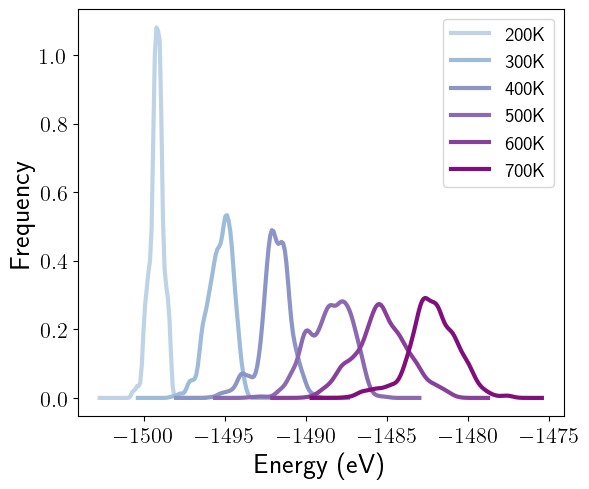

In [3]:
import numpy as np
from scipy.stats import gaussian_kde
cmap2 = matplotlib.cm.get_cmap('BuPu')

total_e = []

for temp in [200,300,400,500,600,700]:
    data=np.load('./LLZO/pure/MD_'+str(temp)+'.npz')
    x=np.arange(min(data['E'])-2,max(data['E'])+2,0.1)
    kernel = gaussian_kde(data['E'])
    print(temp,np.std(data['E']))
    plt.plot(x,kernel(x),'-',color=cmap2(temp/800),label=str(temp)+'K',lw=3)
    
    if temp in [200,300,400]:
        total_e+= [i for i in data['E']]
    
#data=np.load('./LLZO/pure/disp_uniform.npz')
#x=np.arange(min(data['E'])-50,min(data['E'])+300)
#kernel = gaussian_kde(data['E'])
#plt.plot(x,kernel(x),'-',color='b',label='uniform')

print('200-400K, stdev in E:', np.std(total_e))

plt.xlabel('Energy (eV)')
plt.ylabel('Frequency')

plt.legend()
plt.tight_layout()
plt.savefig('MD_energy_distributions.pdf')

/var/folders/tw/q955b5d55gn3m9tkc27d9b440000gq/T/ipykernel_132/4070272761.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap2 = matplotlib.cm.get_cmap('BuPu')


200 0.4827196829488007
300 0.6024486589264059
400 0.6984101492623493
500 0.7849924838924628
600 0.8589371812284113
700 0.9288266583343057


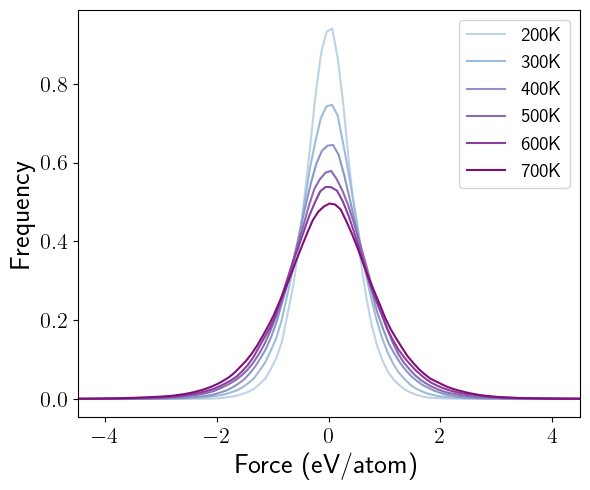

In [3]:
import numpy as np
from scipy.stats import gaussian_kde
cmap2 = matplotlib.cm.get_cmap('BuPu')

total_f=[]
for temp in [200,300,400,500,600,700]:
    data=np.load('./LLZO/pure/MD_'+str(temp)+'.npz')
    F=np.ndarray.flatten(data['F'])
    x=np.arange(min(F)-1,max(F)+1,0.1)
    kernel = gaussian_kde(F)
    print(temp,np.std(F))
    plt.plot(x,kernel(x),'-',color=cmap2(temp/800),label=str(temp)+'K')

plt.xlabel('Force (eV/atom)')
plt.ylabel('Frequency')
plt.xlim([-4.5,4.5])
plt.legend()
plt.tight_layout()
plt.savefig('MD_force_distributions.pdf')

-1505.42619893
-1497.30465109


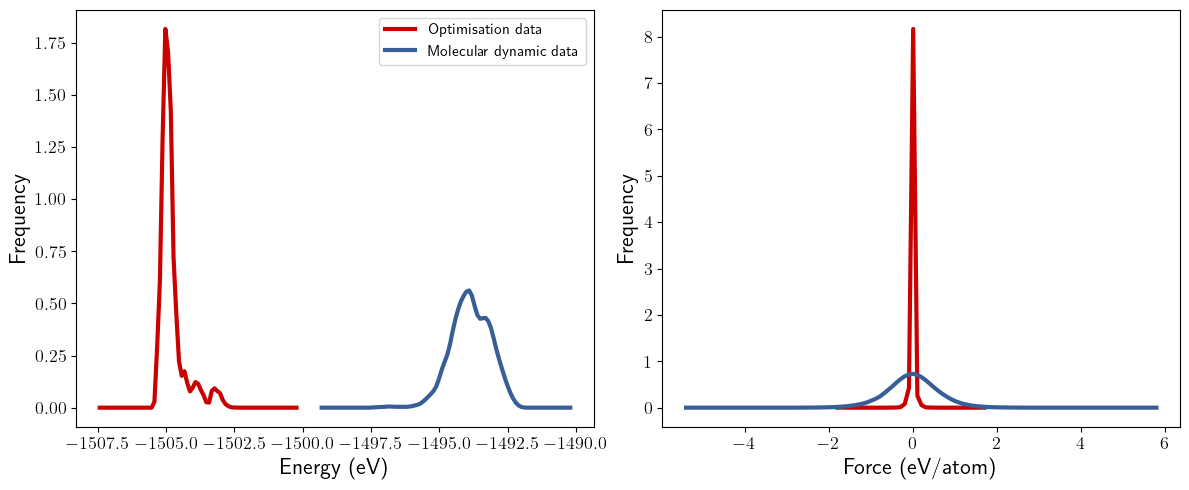

In [2]:
data=np.load('./LLZO/llzo_12_44/opt_data_cLLZO_12_44.npz')
x=np.arange(min(data['E'])-2,max(data['E'])+2,0.1)

print(min(data['E']))
kernel = gaussian_kde(data['E'])
plt.subplot(1,2,1)
plt.plot(x,kernel(x),'-',color='#cb0000',lw=3,label='Optimisation data')
#plt.xlabel('Energy (eV)')
#plt.ylabel('Frequency')

F=np.ndarray.flatten(data['F'])
x=np.arange(min(F)-1,max(F)+1,0.1)
kernel = gaussian_kde(F)

plt.subplot(1,2,2)
plt.plot(x,kernel(x),'-',color='#cb0000',lw=3)

data=np.load('./LLZO/llzo_12_44/md_300K_test.npz')
x=np.arange(min(data['E'])-2,max(data['E'])+2,0.1)

print(min(data['E']))
kernel = gaussian_kde(data['E'])
plt.subplot(1,2,1)
plt.plot(x,kernel(x),'-',color='#375e97',lw=3,label='Molecular dynamic data')
plt.legend()
plt.xlabel('Energy (eV)')
plt.ylabel('Frequency')

F=np.ndarray.flatten(data['F'])
x=np.arange(min(F)-1,max(F)+1,0.1)
kernel = gaussian_kde(F)

plt.subplot(1,2,2)
plt.plot(x,kernel(x),'-',color='#375e97',lw=3)

plt.xlabel('Force (eV/atom)')
plt.ylabel('Frequency')

plt.tight_layout()
#plt.savefig('LLZO_12_44_optimisation_E_F_distributions.pdf')

-1505.17247478


Text(0, 0.5, 'Frequency')

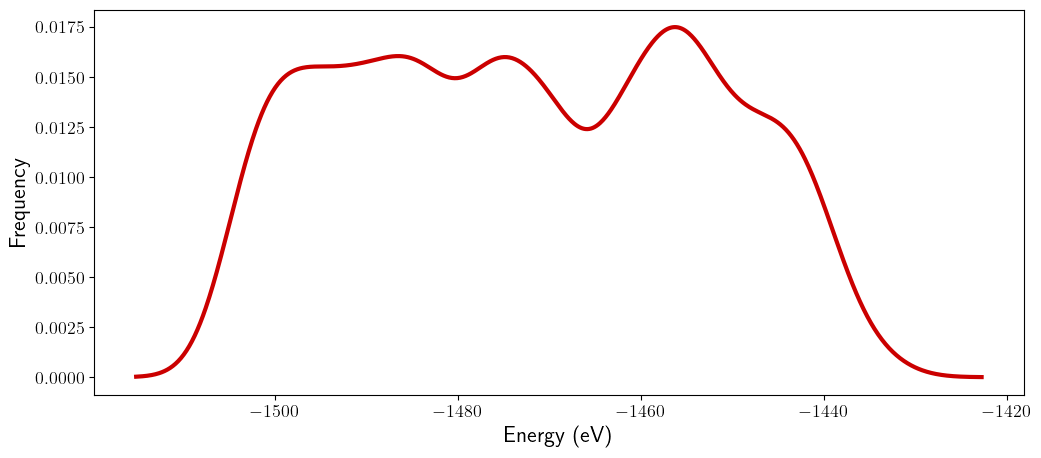

In [4]:
data=np.load('./LLZO/llzo_12_44/all_data_warmup_MD.npz')
x=np.arange(min(data['E'])-10,max(data['E'])+10,0.1)

print(min(data['E']))
kernel = gaussian_kde(data['E'])

plt.plot(x,kernel(x),'-',color='#cb0000',lw=3,label='Optimisation data')
plt.xlabel('Energy (eV)')
plt.ylabel('Frequency')